In [1]:
# ============================================================
# TASK 2 — STAGE 1: DATASET LOADING
# ============================================================

import pandas as pd

DATA_PATH = "/kaggle/input/datasets/abdulsami324243/iris-dataset/Iris.csv"

# Safety: verify the file exists before reading
import os
if not os.path.exists(DATA_PATH):
    print("Path not found. Searching /kaggle/input for Iris.csv ...")
    for root, dirs, files in os.walk("/kaggle/input"):
        for f in files:
            if f.lower() == "iris.csv":
                DATA_PATH = os.path.join(root, f)
                print("Found at:", DATA_PATH)

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head())

Shape: (150, 6)
Columns: ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa


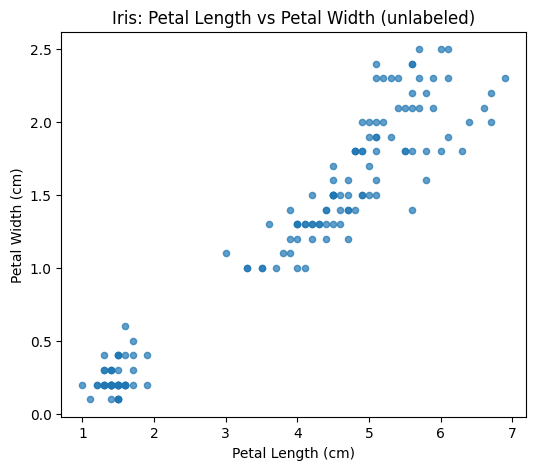

In [2]:
# ============================================================
# TASK 2 — STAGE 2: VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))
plt.scatter(df["PetalLengthCm"], df["PetalWidthCm"], s=20, alpha=0.7)
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Iris: Petal Length vs Petal Width (unlabeled)")
plt.show()

In [3]:
# ============================================================
# TASK 2 — STAGE 3: PREPROCESSING
# ============================================================

# Use only the 4 numeric measurement columns.
# Do NOT include 'Species' — that's the true label for Stage 6.
feature_cols = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
X = df[feature_cols].values

print("Feature matrix shape:", X.shape)
print("First 3 rows:\n", X[:3])

Feature matrix shape: (150, 4)
First 3 rows:
 [[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]]


In [4]:
# ============================================================
# TASK 2 — STAGE 4: TRAINING
# ============================================================

from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(X)

print("Cluster centers (4 features each):")
print(kmeans.cluster_centers_)

Cluster centers (4 features each):
[[5.9016129  2.7483871  4.39354839 1.43387097]
 [5.006      3.418      1.464      0.244     ]
 [6.85       3.07368421 5.74210526 2.07105263]]


In [5]:
# ============================================================
# TASK 2 — STAGE 5: TESTING
# ============================================================

df["Cluster"] = kmeans.predict(X)
print("Cluster sizes:")
print(df["Cluster"].value_counts().sort_index())

Cluster sizes:
Cluster
0    62
1    50
2    38
Name: count, dtype: int64
